In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the new dataset

df = pd.read_csv("C:\\Users\\pro\\Student-Performance-Prediction\\dataset\\StudentPerformanceFactors.csv")

# Display first five records

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
# Display dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names

print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information

print("\nDataset Information:")
df.info()

Number of Rows: 6607
Number of Columns: 20

Column Names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null 

In [4]:
# Statistical summary of numerical columns

df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [5]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical columns

categorical_columns = df.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Categorical Columns:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


C:\Users\pro\AppData\Local\Temp\ipykernel_19504\107178669.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns.tolist()


In [6]:
# Missing value analysis

missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[missing_values["Missing Values"] > 0]

print(missing_values)

                          Missing Values  Percentage
Teacher_Quality                       78    1.180566
Parental_Education_Level              90    1.362192
Distance_from_Home                    67    1.014076


In [7]:
# Check duplicate rows

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


Target Variable: Exam_Score

Target Statistics:
count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64


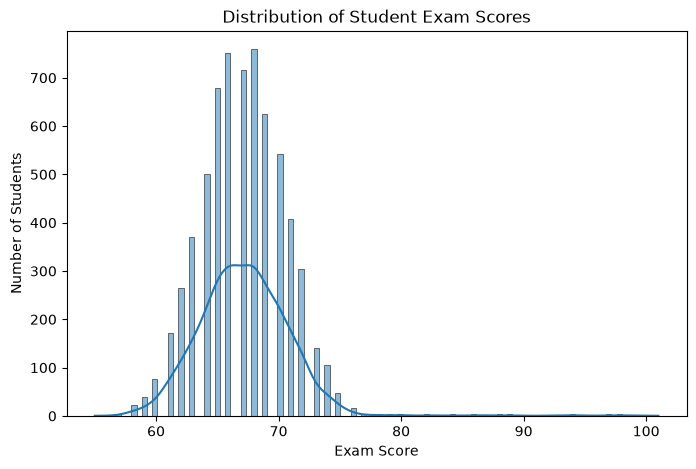

In [8]:
# Analyse target variable

print("Target Variable: Exam_Score")

print("\nTarget Statistics:")
print(df["Exam_Score"].describe())

# Visualize target distribution

plt.figure(figsize=(8, 5))
sns.histplot(df["Exam_Score"], kde=True)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

In [9]:
print("Total duplicate records:", df.duplicated().sum())

Total duplicate records: 0


In [10]:
# Find records with scores above 100

high_scores = df[df["Exam_Score"] > 100]

print("Number of scores above 100:", len(high_scores))

display(high_scores)

Number of scores above 100: 1


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [11]:
print("Scores below 0:", (df["Exam_Score"] < 0).sum())
print("Scores equal to 100:", (df["Exam_Score"] == 100).sum())
print("Scores above 100:", (df["Exam_Score"] > 100).sum())

Scores below 0: 0
Scores equal to 100: 1
Scores above 100: 1


In [12]:
categorical_columns = df.select_dtypes(
    include=["object", "str"]
).columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts(dropna=False))


Column: Parental_Involvement
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

Column: Access_to_Resources
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

Column: Extracurricular_Activities
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

Column: Motivation_Level
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

Column: Internet_Access
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

Column: Family_Income
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

Column: Teacher_Quality
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

Column: School_Type
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

Column: Peer_Influence
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int6

In [13]:
for column, dtype in df.dtypes.items():
    print(f"{column}: {dtype}")

Hours_Studied: int64
Attendance: int64
Parental_Involvement: str
Access_to_Resources: str
Extracurricular_Activities: str
Sleep_Hours: int64
Previous_Scores: int64
Motivation_Level: str
Internet_Access: str
Tutoring_Sessions: int64
Family_Income: str
Teacher_Quality: str
School_Type: str
Peer_Influence: str
Physical_Activity: int64
Learning_Disabilities: str
Parental_Education_Level: str
Distance_from_Home: str
Gender: str
Exam_Score: int64


In [14]:
# Numerical feature range analysis

numerical_columns = df.select_dtypes(include=np.number).columns

for column in numerical_columns:
    print("\nColumn:", column)
    print("Minimum:", df[column].min())
    print("Maximum:", df[column].max())
    print("Mean:", round(df[column].mean(), 2))
    print("Missing Values:", df[column].isnull().sum())


Column: Hours_Studied
Minimum: 1
Maximum: 44
Mean: 19.98
Missing Values: 0

Column: Attendance
Minimum: 60
Maximum: 100
Mean: 79.98
Missing Values: 0

Column: Sleep_Hours
Minimum: 4
Maximum: 10
Mean: 7.03
Missing Values: 0

Column: Previous_Scores
Minimum: 50
Maximum: 100
Mean: 75.07
Missing Values: 0

Column: Tutoring_Sessions
Minimum: 0
Maximum: 8
Mean: 1.49
Missing Values: 0

Column: Physical_Activity
Minimum: 0
Maximum: 6
Mean: 2.97
Missing Values: 0

Column: Exam_Score
Minimum: 55
Maximum: 101
Mean: 67.24
Missing Values: 0


In [15]:
# Check categorical columns for missing values

categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(
        column,
        "-> Missing:",
        df[column].isnull().sum(),
        "| Unique:",
        df[column].nunique()
    )

Parental_Involvement -> Missing: 0 | Unique: 3
Access_to_Resources -> Missing: 0 | Unique: 3
Extracurricular_Activities -> Missing: 0 | Unique: 2
Motivation_Level -> Missing: 0 | Unique: 3
Internet_Access -> Missing: 0 | Unique: 2
Family_Income -> Missing: 0 | Unique: 3
Teacher_Quality -> Missing: 78 | Unique: 3
School_Type -> Missing: 0 | Unique: 2
Peer_Influence -> Missing: 0 | Unique: 3
Learning_Disabilities -> Missing: 0 | Unique: 2
Parental_Education_Level -> Missing: 90 | Unique: 3
Distance_from_Home -> Missing: 67 | Unique: 3
Gender -> Missing: 0 | Unique: 2


C:\Users\pro\AppData\Local\Temp\ipykernel_19504\174595935.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [17]:
# Day 04 Dataset Understanding Summary

print("STUDENT PERFORMANCE DATASET REPORT")
print("-" * 45)

print("Total Records:", df.shape[0])
print("Total Features:", df.shape[1] - 1)
print("Target Variable: Exam_Score")

print("\nNumerical Features:")
print(len(numerical_columns))

print("\nCategorical Features:")
print(len(categorical_columns))

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("Duplicate Records:", df.duplicated().sum())

print(
    "Scores Above 100:",
    (df["Exam_Score"] > 100).sum()
)

print("\nDataset Understanding Completed.")

STUDENT PERFORMANCE DATASET REPORT
---------------------------------------------
Total Records: 6607
Total Features: 19
Target Variable: Exam_Score

Numerical Features:
7

Categorical Features:
13

Total Missing Values: 235
Duplicate Records: 0
Scores Above 100: 1

Dataset Understanding Completed.
